# Clasificación de residuos electrónicos con EfficientNet-B0

**Actividad 2 — Ejecución, optimización y validación comparativa**  
**Técnicas Avanzadas de Modelado en Inteligencia Artificial · Unidad 4**

**Integrantes**  
Sebastian Mejia Ortiz  
Laura Mariana Jimenez Mienez  
Luis Gonzalo Duran

**Docente:** Oscar Alberto Rodriguez Melendez  
**Fecha:** 17 de octubre de 2026

---

Este notebook implementa de principio a fin el pipeline avanzado para clasificar siete categorías de residuos electrónicos del conjunto ETID. Incluye auditoría de las particiones, entrenamiento controlado, ajuste fino, curvas de aprendizaje, selección mediante validación, evaluación final y comparación con la línea base de la Actividad 1.

## Cómo ejecutar

1. Seleccionar el kernel `Python 3 (hoddi2)`.
2. Ejecutar todas las celdas en orden.
3. Mantener `RUN_FULL_PIPELINE = True` en la primera ejecución.
4. Guardar el notebook con todas las salidas visibles.

La primera ejecución entrena tres configuraciones y realiza el ajuste fino; puede tardar varios minutos según la GPU. Cada etapa guarda checkpoints e historiales en `06_ejecucion_notebook`, por lo que una segunda ejecución reutiliza resultados completos y no repite el test. El dataset y las particiones provienen de la Actividad 1; el pipeline avanzado está desarrollado íntegramente aquí.

In [1]:
from __future__ import annotations

import csv
import hashlib
import json
import os
import platform
import random
import shutil
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torchvision
from IPython.display import display
from PIL import Image, ImageOps
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0

SEED = 20261017
CLASSES = ["Battery", "Cable", "Keyboard", "Laptop", "Mobile", "Mouse", "PCB"]
CLASS_TO_INDEX = {label: index for index, label in enumerate(CLASSES)}
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

RUN_FULL_PIPELINE = True
REUSE_COMPLETED_STAGES = True
BATCH_SIZE = 32
NUM_WORKERS = 0  # opción estable para Jupyter sobre Windows
MAX_EPOCHS = 6
PATIENCE = 2
MIN_DELTA = 0.002

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")

In [2]:
def locate_project_root(start: Path):
    # Admite tanto el repositorio publicable como la estructura histórica del curso.
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "configs" / "experiments.json").exists() and (candidate / "docs").is_dir():
            return candidate, "repository"
        if (candidate / "01_prueba_real").is_dir() and (candidate / "02_experimentos_controlados").is_dir():
            return candidate, "legacy"
        nested = candidate / "Proyecto_ETID"
        if (nested / "01_prueba_real").is_dir():
            return nested, "legacy"
    raise FileNotFoundError("No se encontró la raíz del proyecto o del repositorio ETID.")


PROJECT_ROOT, PROJECT_MODE = locate_project_root(Path.cwd())
if PROJECT_MODE == "repository":
    default_data = PROJECT_ROOT / "data" / "raw" / "ETID"
    DATA_ROOT = Path(os.getenv("ETID_DATA_ROOT", default_data)).expanduser().resolve()
    SPLITS_ROOT = PROJECT_ROOT / "data" / "splits"
    BASELINE_ROOT = PROJECT_ROOT / "results" / "baseline"
    RUN_ROOT = PROJECT_ROOT / "results" / "advanced"
else:
    unit4_root = PROJECT_ROOT.parents[1]
    activity1_root = unit4_root / "Actividad 1" / "E_Tadweer_ETID"
    DATA_ROOT = activity1_root / "datos" / "E-Tadweer Image Dataset (ETID)"
    SPLITS_ROOT = activity1_root / "preparacion_experimental" / "particiones"
    BASELINE_ROOT = activity1_root / "linea_base"
    RUN_ROOT = PROJECT_ROOT / "06_ejecucion_notebook"

RUN_ROOT.mkdir(parents=True, exist_ok=True)
os.environ["TORCH_HOME"] = str((PROJECT_ROOT / ".torch").resolve())

required = [
    DATA_ROOT,
    SPLITS_ROOT / "train.csv",
    SPLITS_ROOT / "validation.csv",
    SPLITS_ROOT / "test.csv",
    BASELINE_ROOT / "resultados_baseline.json",
    BASELINE_ROOT / "predicciones_test.csv",
]
missing = [str(path) for path in required if not path.exists()]
assert not missing, (
    "Faltan recursos. Consulte data/README.md o defina ETID_DATA_ROOT. "
    f"Elementos no encontrados: {missing}"
)

display(pd.DataFrame({
    "Recurso": ["Modo", "Dataset", "Particiones", "Línea base", "Resultados avanzados"],
    "Estado": [
        PROJECT_MODE,
        "Disponible",
        "Disponibles",
        "Disponible",
        "Carpeta preparada",
    ],
}))

,Recurso,Estado
0,Modo,repository
1,Dataset,Disponible
2,Particiones,Disponibles
3,Línea base,Disponible
4,Resultados avanzados,Carpeta preparada


In [3]:
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

environment = pd.DataFrame({
    "Componente": ["Python", "PyTorch", "Torchvision", "scikit-learn", "Dispositivo", "GPU"],
    "Versión o estado": [
        sys.version.split()[0], torch.__version__, torchvision.__version__, sklearn.__version__,
        DEVICE.type,
        torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No disponible",
    ],
})
display(environment)

,Componente,Versión o estado
0,Python,3.10.18
1,PyTorch,2.6.0+cu126
2,Torchvision,0.21.0+cu126
3,scikit-learn,1.7.2
4,Dispositivo,cuda
5,GPU,NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Auditoría de entrenamiento y validación

La separación por grupos se definió en la Actividad 1 para evitar que imágenes relacionadas aparecieran en particiones distintas. En esta etapa se revisan únicamente entrenamiento y validación. El archivo de test existe, pero sus etiquetas no se cargan hasta que el modelo queda seleccionado.

,Partición,Imágenes,Grupos,SHA-256
0,train,4289,16,b0759318003bab059154a48de9e1bff47fbc02cb4e70e7...
1,validation,983,6,bb17b6d7c7d398d02f847b2114d5d574e028dd8756a17a...


,train,validation
etiqueta_final,,
Battery,1007,201
Cable,127,34
Keyboard,365,249
Laptop,376,72
Mobile,776,179
Mouse,803,187
PCB,835,61


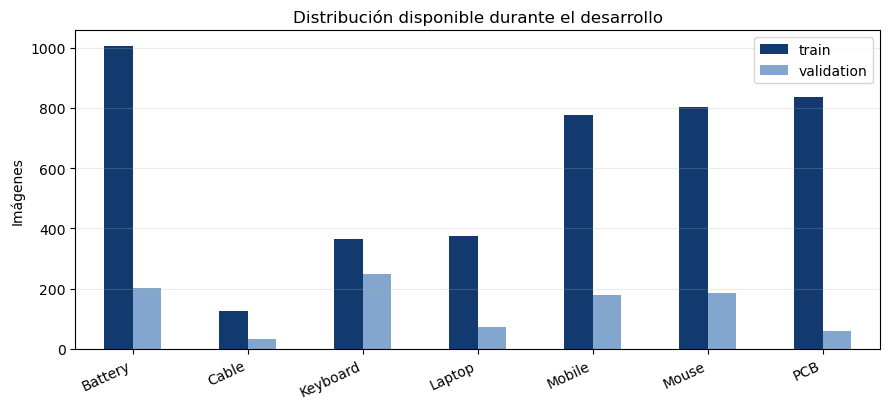

In [4]:
def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def read_manifest(name: str) -> pd.DataFrame:
    return pd.read_csv(SPLITS_ROOT / f"{name}.csv")


train_frame = read_manifest("train")
validation_frame = read_manifest("validation")

train_groups = set(train_frame["grupo_particion"])
validation_groups = set(validation_frame["grupo_particion"])
assert train_groups.isdisjoint(validation_groups), "Hay grupos compartidos entre train y validation."
assert set(train_frame["etiqueta_final"]) == set(CLASSES)
assert set(validation_frame["etiqueta_final"]) == set(CLASSES)

audit = pd.DataFrame([
    {
        "Partición": "train",
        "Imágenes": len(train_frame),
        "Grupos": train_frame["grupo_particion"].nunique(),
        "SHA-256": sha256(SPLITS_ROOT / "train.csv"),
    },
    {
        "Partición": "validation",
        "Imágenes": len(validation_frame),
        "Grupos": validation_frame["grupo_particion"].nunique(),
        "SHA-256": sha256(SPLITS_ROOT / "validation.csv"),
    },
])
display(audit)

distribution = pd.concat([
    train_frame["etiqueta_final"].value_counts().rename("train"),
    validation_frame["etiqueta_final"].value_counts().rename("validation"),
], axis=1).fillna(0).astype(int).reindex(CLASSES)
display(distribution)

ax = distribution.plot(kind="bar", figsize=(9, 4.2), color=["#123a6f", "#83a6ce"])
ax.set_title("Distribución disponible durante el desarrollo")
ax.set_xlabel("")
ax.set_ylabel("Imágenes")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 2. Preparación de imágenes

El redimensionamiento conserva la relación de aspecto mediante *letterbox*. El aumento de datos se aplica solo a entrenamiento: reflejo horizontal, rotación moderada y cambios suaves de brillo y contraste. Validación y test usan una transformación determinista. La normalización corresponde a los pesos de ImageNet empleados para transferencia de aprendizaje.

In [5]:
class Letterbox:
    def __init__(self, size=224, fill=(0, 0, 0)):
        self.size = size
        self.fill = fill

    def __call__(self, image):
        image = ImageOps.exif_transpose(image).convert("RGB")
        width, height = image.size
        scale = min(self.size / width, self.size / height)
        resized = image.resize(
            (max(1, round(width * scale)), max(1, round(height * scale))),
            Image.Resampling.BILINEAR,
        )
        canvas = Image.new("RGB", (self.size, self.size), self.fill)
        canvas.paste(resized, ((self.size - resized.width) // 2, (self.size - resized.height) // 2))
        return canvas


class ETIDDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        route = row["ruta"]
        with Image.open(DATA_ROOT / route) as image:
            tensor = self.transform(image)
        return tensor, CLASS_TO_INDEX[row["etiqueta_final"]], route


train_transform = transforms.Compose([
    Letterbox(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=8, fill=0),
    transforms.ColorJitter(brightness=0.12, contrast=0.12),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
evaluation_transform = transforms.Compose([
    Letterbox(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def make_loaders(train_data=train_frame, validation_data=validation_frame):
    common = {
        "batch_size": BATCH_SIZE,
        "num_workers": NUM_WORKERS,
        "pin_memory": DEVICE.type == "cuda",
        "persistent_workers": NUM_WORKERS > 0,
    }
    train_loader = DataLoader(
        ETIDDataset(train_data, train_transform),
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
        **common,
    )
    validation_loader = DataLoader(
        ETIDDataset(validation_data, evaluation_transform), shuffle=False, **common
    )
    return train_loader, validation_loader


train_counts = train_frame["etiqueta_final"].value_counts()
class_weights = torch.tensor(
    [len(train_frame) / (len(CLASSES) * train_counts[label]) for label in CLASSES],
    dtype=torch.float32,
    device=DEVICE,
)
display(pd.DataFrame({"Clase": CLASSES, "Peso en la pérdida": class_weights.cpu().numpy()}))

,Clase,Peso en la pérdida
0,Battery,0.6085
1,Cable,4.8245
2,Keyboard,1.6787
3,Laptop,1.6296
4,Mobile,0.7896
5,Mouse,0.7630
6,PCB,0.7338


## 3. Métricas, arquitectura y ciclo de entrenamiento

F1 macro es la métrica de selección porque trata cada categoría con el mismo peso. Se complementa con exactitud balanceada y exactitud global. EfficientNet-B0 equilibra profundidad, anchura y resolución mediante escalamiento compuesto (Tan & Le, 2019). Sus bloques MBConv emplean convoluciones separables y mecanismos *squeeze-and-excitation* para aprender representaciones con un costo moderado. La salida original se reemplaza por una cabeza de siete neuronas, una por clase.

Durante la primera etapa se congela el extractor para conservar las representaciones generales aprendidas en ImageNet. El ajuste fino habilita únicamente `features[7]`, `features[8]` y la cabeza: estos componentes concentran rasgos de alto nivel y permiten adaptación al dominio sin alterar toda la red. La regularización, la parada temprana y el seguimiento separado de entrenamiento y validación responden a prácticas estándar para controlar la generalización (Goodfellow et al., 2016).

In [6]:
def metric_dict(truth, predicted):
    return {
        "accuracy": float(accuracy_score(truth, predicted)),
        "balanced_accuracy": float(balanced_accuracy_score(truth, predicted)),
        "precision_macro": float(precision_score(truth, predicted, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(truth, predicted, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(truth, predicted, average="macro", zero_division=0)),
    }


def build_model(dropout=0.2, pretrained=True):
    weights = EfficientNet_B0_Weights.DEFAULT if pretrained else None
    model = efficientnet_b0(weights=weights)
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_features, len(CLASSES)))
    return model.to(DEVICE).to(memory_format=torch.channels_last)


preview_model = build_model(dropout=0.2)
architecture = pd.DataFrame({
    "Elemento": ["Modelo", "Entrada", "Salida", "Parámetros totales", "Función de pérdida"],
    "Valor": [
        "EfficientNet-B0", "224 × 224 × 3", "7 clases",
        f"{sum(parameter.numel() for parameter in preview_model.parameters()):,}",
        "Entropía cruzada ponderada",
    ],
})
display(architecture)
del preview_model
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

stage_table = pd.DataFrame([
    {"Etapa": "Stem", "Función": "Bordes y patrones iniciales", "Tratamiento": "Preentrenada y congelada"},
    {"Etapa": "MBConv tempranos", "Función": "Texturas y formas generales", "Tratamiento": "Congelados"},
    {"Etapa": "features[7] y features[8]", "Función": "Rasgos visuales de alto nivel", "Tratamiento": "Candidatos a ajuste fino"},
    {"Etapa": "Global average pooling", "Función": "Resumen espacial compacto", "Tratamiento": "Operación original"},
    {"Etapa": "Dropout + Linear", "Función": "Regularización y siete salidas", "Tratamiento": "Entrenada desde cero"},
])
display(stage_table)

,Elemento,Valor
0,Modelo,EfficientNet-B0
1,Entrada,224 × 224 × 3
2,Salida,7 clases
3,Parámetros totales,"4,016,515"
4,Función de pérdida,Entropía cruzada ponderada


,Etapa,Función,Tratamiento
0,Stem,Bordes y patrones iniciales,Preentrenada y congelada
1,MBConv tempranos,Texturas y formas generales,Congelados
2,features[7] y features[8],Rasgos visuales de alto nivel,Candidatos a ajuste fino
3,Global average pooling,Resumen espacial compacto,Operación original
4,Dropout + Linear,Regularización y siete salidas,Entrenada desde cero


In [7]:
def set_train_mode(model, stage):
    model.train()
    if stage == "head":
        model.features.eval()
    elif stage == "finetune":
        for block in model.features[:-2]:
            block.eval()


def train_one_epoch(model, loader, criterion, optimizer, scaler, stage):
    set_train_mode(model, stage)
    losses, truth, predicted = [], [], []
    started = time.perf_counter()
    trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
    for step, (images, labels, _) in enumerate(loader, start=1):
        images = images.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(trainable, max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        losses.append(float(loss.detach()))
        truth.extend(labels.detach().cpu().tolist())
        predicted.extend(logits.argmax(dim=1).detach().cpu().tolist())
        if step % 50 == 0 or step == len(loader):
            print(f"  lote {step:>3}/{len(loader)} · pérdida reciente {np.mean(losses[-20:]):.4f}", flush=True)
    return {"loss": float(np.mean(losses)), **metric_dict(truth, predicted), "seconds": time.perf_counter() - started}


@torch.inference_mode()
def evaluate(model, loader, criterion):
    model.eval()
    losses, truth, predicted, rows = [], [], [], []
    started = time.perf_counter()
    for images, labels, routes in loader:
        images = images.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        labels = labels.to(DEVICE, non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)
        probabilities = torch.softmax(logits.float(), dim=1)
        batch_pred = probabilities.argmax(dim=1)
        losses.append(float(loss))
        truth.extend(labels.cpu().tolist())
        predicted.extend(batch_pred.cpu().tolist())
        for route, true, pred, confidence in zip(
            routes, labels.cpu().tolist(), batch_pred.cpu().tolist(), probabilities.max(1).values.cpu().tolist()
        ):
            rows.append({
                "ruta": route,
                "etiqueta_real": CLASSES[true],
                "prediccion": CLASSES[pred],
                "confianza": confidence,
                "correcta": int(true == pred),
            })
    return (
        {"loss": float(np.mean(losses)), **metric_dict(truth, predicted), "seconds": time.perf_counter() - started},
        pd.DataFrame(rows), truth, predicted,
    )


def plot_history(history, title):
    frame = pd.DataFrame(history)
    trained = frame[frame["epoch"] > 0]
    figure, axes = plt.subplots(1, 3, figsize=(15, 4.1))
    for axis, metric, label in zip(
        axes,
        ["loss", "accuracy", "f1_macro"],
        ["Pérdida", "Exactitud", "F1 macro"],
    ):
        if not trained.empty:
            axis.plot(trained["epoch"], trained[f"train_{metric}"], marker="o", label="Entrenamiento")
        axis.plot(frame["epoch"], frame[f"validation_{metric}"], marker="o", label="Validación")
        axis.set_title(label)
        axis.set_xlabel("Época")
        axis.grid(alpha=0.25)
        if metric != "loss":
            axis.set_ylim(0, 1)
        axis.legend()
    figure.suptitle(title)
    figure.tight_layout()
    plt.show()


def save_json(path, value):
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")

## 4. Experimentos controlados

Se modifica un solo factor por experimento. E01 es la referencia; E02 reduce la tasa de aprendizaje para comprobar si pasos más pequeños estabilizan la validación, y E03 aumenta el *dropout* para evaluar si una regularización mayor limita la memorización. Las particiones, el aumento de datos, la pérdida, el optimizador y la semilla permanecen constantes. Se aplica parada temprana con paciencia de dos épocas y una mejora mínima de 0,002 en F1 macro.

AdamW se fijó antes de observar resultados para no mezclar el efecto del optimizador con los dos factores estudiados. La búsqueda deliberadamente pequeña y de un factor por vez sigue el enfoque de optimización científica recomendado por Google Developers (s. f.). Comparar otro optimizador después de haber abierto el test constituiría un nuevo ciclo experimental y no se utilizará para alterar el resultado de esta entrega.

In [8]:
EXPERIMENTS = [
    {"id": "E01_lr1e-3_drop02", "learning_rate": 1e-3, "dropout": 0.2, "change": "Referencia"},
    {"id": "E02_lr3e-4_drop02", "learning_rate": 3e-4, "dropout": 0.2, "change": "Menor tasa de aprendizaje"},
    {"id": "E03_lr1e-3_drop04", "learning_rate": 1e-3, "dropout": 0.4, "change": "Mayor dropout"},
]


def run_head_experiment(config):
    output = RUN_ROOT / config["id"]
    output.mkdir(parents=True, exist_ok=True)
    result_path = output / "result.json"
    checkpoint_path = output / "best_checkpoint.pt"
    if REUSE_COMPLETED_STAGES and result_path.exists() and checkpoint_path.exists():
        cached = json.loads(result_path.read_text(encoding="utf-8"))
        if cached.get("status") == "COMPLETE" and cached.get("config") == config:
            print(f"{config['id']}: etapa completa; se reutiliza.")
            return cached

    seed_everything()
    train_loader, validation_loader = make_loaders()
    model = build_model(config["dropout"])
    for parameter in model.features.parameters():
        parameter.requires_grad = False
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW(
        model.classifier.parameters(), lr=config["learning_rate"], weight_decay=1e-4
    )
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
    history, best_f1, best_epoch, patience_count = [], -1.0, 0, 0

    for epoch in range(1, MAX_EPOCHS + 1):
        print(f"{config['id']} · época {epoch}/{MAX_EPOCHS}")
        train_metrics = train_one_epoch(model, train_loader, criterion, optimizer, scaler, "head")
        validation_metrics, predictions, truth, predicted = evaluate(model, validation_loader, criterion)
        row = {
            "epoch": epoch,
            **{f"train_{key}": value for key, value in train_metrics.items()},
            **{f"validation_{key}": value for key, value in validation_metrics.items()},
        }
        history.append(row)
        pd.DataFrame(history).to_csv(output / "history.csv", index=False)

        if validation_metrics["f1_macro"] > best_f1 + MIN_DELTA:
            best_f1 = validation_metrics["f1_macro"]
            best_epoch = epoch
            patience_count = 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "config": config,
                "validation_metrics": validation_metrics,
                "classes": CLASSES,
                "seed": SEED,
            }, checkpoint_path)
            predictions.to_csv(output / "best_validation_predictions.csv", index=False)
        else:
            patience_count += 1
        print(f"  F1 validación {validation_metrics['f1_macro']:.4f} · mejor {best_f1:.4f}")
        if patience_count >= PATIENCE:
            print("  Parada temprana.")
            break

    best_row = history[best_epoch - 1]
    result = {
        "status": "COMPLETE",
        "config": config,
        "best_epoch": best_epoch,
        "epochs_completed": len(history),
        "best_validation_f1_macro": best_f1,
        "best_validation_accuracy": best_row["validation_accuracy"],
        "best_validation_balanced_accuracy": best_row["validation_balanced_accuracy"],
        "checkpoint_sha256": sha256(checkpoint_path),
        "history": history,
    }
    save_json(result_path, result)
    del model, optimizer, scaler, train_loader, validation_loader
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return result


if not RUN_FULL_PIPELINE:
    raise RuntimeError("Para la entrega ejecutada, RUN_FULL_PIPELINE debe permanecer en True.")

experiment_results = [run_head_experiment(config) for config in EXPERIMENTS]

E01_lr1e-3_drop02: etapa completa; se reutiliza.
E02_lr3e-4_drop02: etapa completa; se reutiliza.
E03_lr1e-3_drop04: etapa completa; se reutiliza.


,Experimento,Cambio controlado,Tasa de aprendizaje,Dropout,Mejor época,Épocas ejecutadas,F1 macro validación,Exactitud balanceada,Exactitud
1,E03_lr1e-3_drop04,Mayor dropout,0.0010,0.4000,1,3,0.8777,0.8949,0.9044
2,E01_lr1e-3_drop02,Referencia,0.0010,0.2000,1,3,0.8770,0.8925,0.9054
3,E02_lr3e-4_drop02,Menor tasa de aprendizaje,0.0003,0.2000,1,3,0.8639,0.8846,0.8942


Configuración seleccionada: E03_lr1e-3_drop04, época 1.


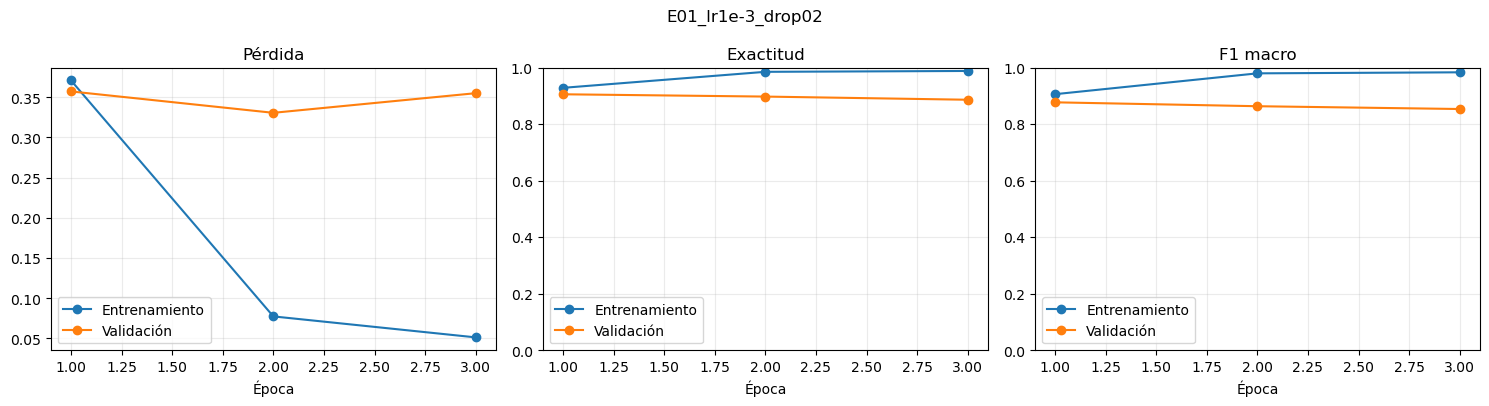

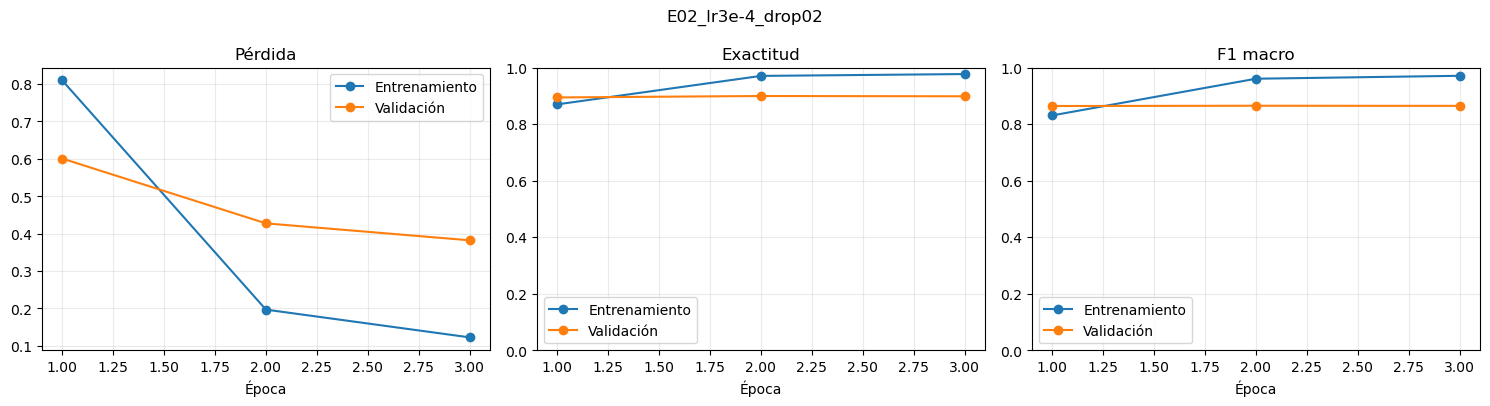

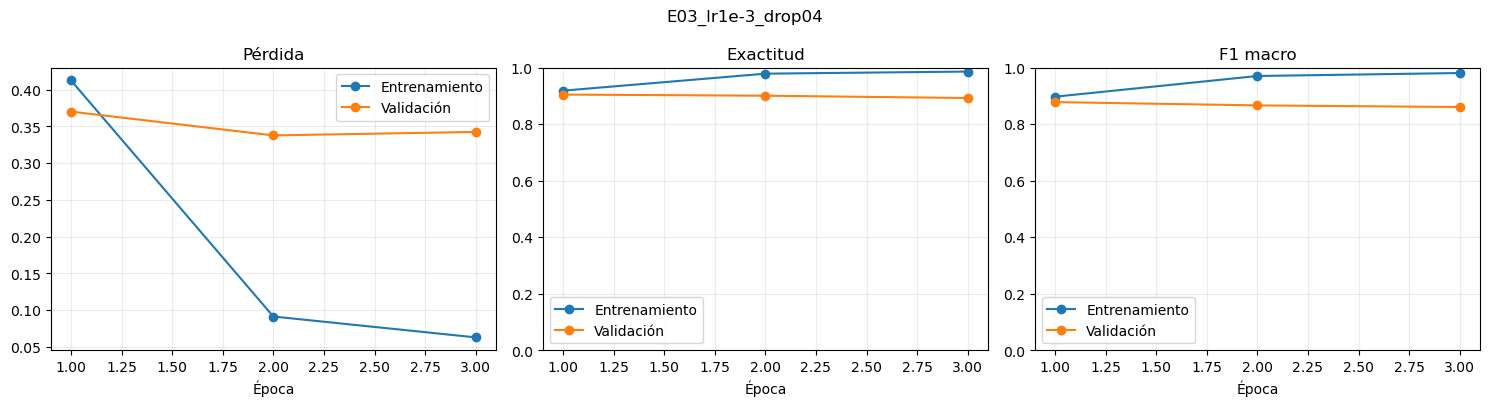

,Experimento,Cambio F1 entrenamiento,Cambio F1 validación,Brecha final F1,Diagnóstico
0,E01_lr1e-3_drop02,0.0774,-0.0237,0.1299,Sobreajuste después de la primera época
1,E02_lr3e-4_drop02,0.1402,0.0005,0.1064,Validación estable; mejora insuficiente para r...
2,E03_lr1e-3_drop04,0.0837,-0.0174,0.1202,Sobreajuste después de la primera época


Margen entre los dos primeros experimentos: 0.0008. La diferencia es pequeña y no se interpreta como superioridad general de una configuración.


In [9]:
ranking = pd.DataFrame([{
    "Experimento": result["config"]["id"],
    "Cambio controlado": result["config"]["change"],
    "Tasa de aprendizaje": result["config"]["learning_rate"],
    "Dropout": result["config"]["dropout"],
    "Mejor época": result["best_epoch"],
    "Épocas ejecutadas": result["epochs_completed"],
    "F1 macro validación": result["best_validation_f1_macro"],
    "Exactitud balanceada": result["best_validation_balanced_accuracy"],
    "Exactitud": result["best_validation_accuracy"],
} for result in experiment_results]).sort_values("F1 macro validación", ascending=False).reset_index(drop=True)
ranking.index = ranking.index + 1
display(ranking)

winner_id = ranking.iloc[0]["Experimento"]
winner_result = next(result for result in experiment_results if result["config"]["id"] == winner_id)
winner_checkpoint = RUN_ROOT / winner_id / "best_checkpoint.pt"
print(f"Configuración seleccionada: {winner_id}, época {winner_result['best_epoch']}.")

for result in experiment_results:
    plot_history(result["history"], result["config"]["id"])

diagnostic_rows = []
for result in experiment_results:
    frame = pd.DataFrame(result["history"])
    first = frame.iloc[0]
    last = frame.iloc[-1]
    validation_change = last["validation_f1_macro"] - first["validation_f1_macro"]
    train_change = last["train_f1_macro"] - first["train_f1_macro"]
    if train_change > 0 and validation_change < -0.01:
        diagnosis = "Sobreajuste después de la primera época"
    elif abs(validation_change) <= 0.01:
        diagnosis = "Validación estable; mejora insuficiente para reemplazar el checkpoint"
    else:
        diagnosis = "Revisar evolución conjunta de pérdida y métricas"
    diagnostic_rows.append({
        "Experimento": result["config"]["id"],
        "Cambio F1 entrenamiento": train_change,
        "Cambio F1 validación": validation_change,
        "Brecha final F1": last["train_f1_macro"] - last["validation_f1_macro"],
        "Diagnóstico": diagnosis,
    })
display(pd.DataFrame(diagnostic_rows))

winner_margin = ranking.iloc[0]["F1 macro validación"] - ranking.iloc[1]["F1 macro validación"]
print(
    f"Margen entre los dos primeros experimentos: {winner_margin:.4f}. "
    "La diferencia es pequeña y no se interpreta como superioridad general de una configuración."
)

Las curvas muestran un patrón común: el desempeño de entrenamiento continúa creciendo después de la primera época, mientras la validación deja de mejorar o retrocede. En E01 y E03 esta separación constituye evidencia de sobreajuste temprano; E02 es más estable, pero no alcanza el mejor F1. E03 ocupa el primer lugar por el criterio predefinido, aunque su ventaja frente a E01 es mínima y debe comunicarse como un resultado prácticamente empatado, no como una superioridad contundente. El test continúa cerrado durante esta decisión.

## 5. Ajuste fino conservador

El checkpoint ganador se usa como punto de partida. Se congelan nuevamente todos los parámetros y se habilitan solo `features[7]`, `features[8]` y la cabeza. Los bloques finales reciben una tasa de `1e-5`; la cabeza, `5e-5`. La época 0 representa el rendimiento anterior al ajuste y funciona como umbral real: el modelo ajustado solo lo reemplaza si mejora al menos 0,002 en F1 macro.

Ajuste fino completo; se reutiliza.


,epoch,train_loss,validation_loss,train_accuracy,validation_accuracy,train_f1_macro,validation_f1_macro
0,0,NaN,0.3701,NaN,0.9044,NaN,0.8777
1,1,0.2204,0.5163,0.9615,0.8850,0.9478,0.8481
2,2,0.1639,0.4207,0.9690,0.8993,0.9618,0.8671


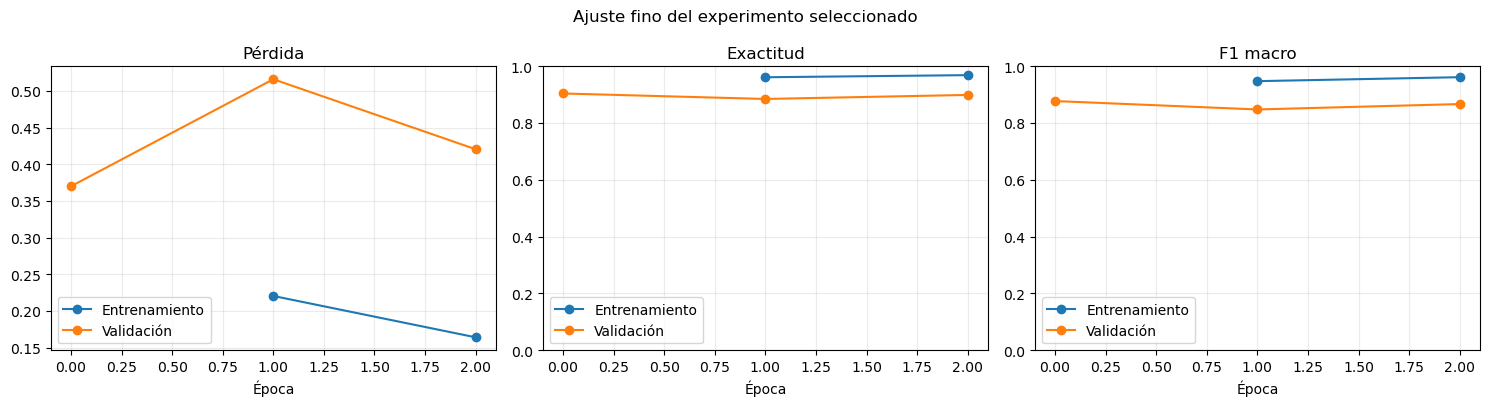

Checkpoint congelado: época 0 · F1 macro de validación 0.8777.
Decisión: el ajuste fino fue rechazado porque redujo el F1 macro de validación. El modelo final conserva el checkpoint de la cabeza entrenada antes de liberar bloques.


In [10]:
def run_finetuning(source_checkpoint):
    output = RUN_ROOT / "ajuste_fino"
    output.mkdir(parents=True, exist_ok=True)
    result_path = output / "result.json"
    selected_path = output / "selected_checkpoint.pt"
    source_hash = sha256(source_checkpoint)
    if REUSE_COMPLETED_STAGES and result_path.exists() and selected_path.exists():
        cached = json.loads(result_path.read_text(encoding="utf-8"))
        if cached.get("status") == "COMPLETE" and cached.get("source_checkpoint_sha256") == source_hash:
            if cached.get("selected_checkpoint_sha256") == sha256(selected_path):
                print("Ajuste fino completo; se reutiliza.")
                return cached, selected_path

    seed_everything()
    train_loader, validation_loader = make_loaders()
    source = torch.load(source_checkpoint, map_location="cpu", weights_only=False)
    model = build_model(source["config"]["dropout"], pretrained=False)
    model.load_state_dict(source["model_state_dict"], strict=True)
    for parameter in model.parameters():
        parameter.requires_grad = False
    for block in model.features[-2:]:
        for parameter in block.parameters():
            parameter.requires_grad = True
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True

    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW([
        {"params": model.features[-2:].parameters(), "lr": 1e-5},
        {"params": model.classifier.parameters(), "lr": 5e-5},
    ], weight_decay=1e-4)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)

    baseline_metrics, baseline_predictions, baseline_truth, baseline_predicted = evaluate(
        model, validation_loader, criterion
    )
    history = [{
        "epoch": 0,
        "train_loss": None,
        "train_accuracy": None,
        "train_f1_macro": None,
        **{f"validation_{key}": value for key, value in baseline_metrics.items()},
    }]
    best_metrics = baseline_metrics
    best_epoch = 0
    patience_count = 0
    shutil.copy2(source_checkpoint, selected_path)

    for epoch in range(1, MAX_EPOCHS + 1):
        print(f"Ajuste fino · época {epoch}/{MAX_EPOCHS}")
        train_metrics = train_one_epoch(model, train_loader, criterion, optimizer, scaler, "finetune")
        validation_metrics, predictions, truth, predicted = evaluate(model, validation_loader, criterion)
        history.append({
            "epoch": epoch,
            **{f"train_{key}": value for key, value in train_metrics.items()},
            **{f"validation_{key}": value for key, value in validation_metrics.items()},
        })
        pd.DataFrame(history).to_csv(output / "history.csv", index=False)
        if validation_metrics["f1_macro"] > best_metrics["f1_macro"] + MIN_DELTA:
            best_metrics = validation_metrics
            best_epoch = epoch
            patience_count = 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "stage": "finetune",
                "dropout": source["config"]["dropout"],
                "validation_metrics": validation_metrics,
                "classes": CLASSES,
                "seed": SEED,
            }, selected_path)
            predictions.to_csv(output / "selected_validation_predictions.csv", index=False)
        else:
            patience_count += 1
        print(f"  F1 validación {validation_metrics['f1_macro']:.4f} · seleccionado {best_metrics['f1_macro']:.4f}")
        if patience_count >= PATIENCE:
            print("  Parada temprana.")
            break

    result = {
        "status": "COMPLETE",
        "source_experiment": source["config"]["id"],
        "source_checkpoint_sha256": source_hash,
        "selected_epoch": best_epoch,
        "baseline_validation": baseline_metrics,
        "selected_validation": best_metrics,
        "delta_f1_macro": best_metrics["f1_macro"] - baseline_metrics["f1_macro"],
        "epochs_completed": len(history) - 1,
        "selected_checkpoint_sha256": sha256(selected_path),
        "history": history,
    }
    save_json(result_path, result)
    del model, optimizer, scaler, train_loader, validation_loader
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return result, selected_path


finetune_result, selected_checkpoint = run_finetuning(winner_checkpoint)
display(pd.DataFrame(finetune_result["history"])[[
    "epoch", "train_loss", "validation_loss", "train_accuracy", "validation_accuracy",
    "train_f1_macro", "validation_f1_macro",
]])
plot_history(finetune_result["history"], "Ajuste fino del experimento seleccionado")
print(
    f"Checkpoint congelado: época {finetune_result['selected_epoch']} · "
    f"F1 macro de validación {finetune_result['selected_validation']['f1_macro']:.4f}."
)

if finetune_result["selected_epoch"] == 0:
    print(
        "Decisión: el ajuste fino fue rechazado porque redujo el F1 macro de validación. "
        "El modelo final conserva el checkpoint de la cabeza entrenada antes de liberar bloques."
    )
else:
    print("Decisión: el ajuste fino superó el umbral y reemplazó al checkpoint de origen.")

## 6. Apertura única del conjunto de prueba

El test se carga solo después de congelar el checkpoint y registrar su hash. No participa en el entrenamiento, la parada temprana ni la elección de hiperparámetros. Si esta celda se ejecuta otra vez con el mismo checkpoint, recupera el resultado guardado; si detecta otro checkpoint, se detiene para impedir una nueva selección indirecta sobre test.

In [11]:
def paired_bootstrap(truth, baseline_predicted, advanced_predicted, repetitions=2000):
    generator = np.random.default_rng(SEED)
    truth = np.asarray(truth)
    baseline_predicted = np.asarray(baseline_predicted)
    advanced_predicted = np.asarray(advanced_predicted)
    differences = []
    for _ in range(repetitions):
        sample = generator.integers(0, len(truth), len(truth))
        differences.append(
            f1_score(truth[sample], advanced_predicted[sample], average="macro", zero_division=0)
            - f1_score(truth[sample], baseline_predicted[sample], average="macro", zero_division=0)
        )
    return {
        "repetitions": repetitions,
        "ci95": [float(np.percentile(differences, 2.5)), float(np.percentile(differences, 97.5))],
        "positive_proportion": float(np.mean(np.asarray(differences) > 0)),
    }


def run_final_test(checkpoint_path):
    output = RUN_ROOT / "evaluacion_final"
    output.mkdir(parents=True, exist_ok=True)
    result_path = output / "result.json"
    checkpoint_hash = sha256(checkpoint_path)
    test_hash = sha256(SPLITS_ROOT / "test.csv")
    if result_path.exists():
        cached = json.loads(result_path.read_text(encoding="utf-8"))
        if cached.get("checkpoint_sha256") != checkpoint_hash or cached.get("test_manifest_sha256") != test_hash:
            raise RuntimeError("Existe una evaluación final asociada a otro checkpoint o manifiesto.")
        print("La evaluación final ya está registrada; no se vuelve a consultar el test.")
        return cached

    print("Checkpoint congelado y verificado. Se abre el test por única vez.")
    test_frame = read_manifest("test")
    test_loader = DataLoader(
        ETIDDataset(test_frame, evaluation_transform),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=DEVICE.type == "cuda",
    )
    stored = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    dropout = stored.get("dropout", stored.get("config", {}).get("dropout", 0.2))
    model = build_model(dropout, pretrained=False)
    model.load_state_dict(stored["model_state_dict"], strict=True)
    criterion = nn.CrossEntropyLoss()
    test_metrics, predictions, truth, predicted = evaluate(model, test_loader, criterion)
    predictions.to_csv(output / "advanced_test_predictions.csv", index=False)

    baseline_result = json.loads((BASELINE_ROOT / "resultados_baseline.json").read_text(encoding="utf-8"))
    assert baseline_result["manifiestos_sha256"]["test"] == test_hash
    baseline_predictions = pd.read_csv(BASELINE_ROOT / "predicciones_test.csv").set_index("ruta")
    baseline_predicted = []
    for row in test_frame.itertuples(index=False):
        baseline_row = baseline_predictions.loc[row.ruta]
        assert baseline_row["etiqueta_real"] == row.etiqueta_final
        baseline_predicted.append(CLASS_TO_INDEX[baseline_row["prediccion"]])

    advanced_class_report = classification_report(
        truth, predicted, labels=range(len(CLASSES)), target_names=CLASSES,
        output_dict=True, zero_division=0,
    )
    per_class = pd.DataFrame([{
        "clase": label,
        "precision": advanced_class_report[label]["precision"],
        "recall": advanced_class_report[label]["recall"],
        "f1": advanced_class_report[label]["f1-score"],
        "soporte": int(advanced_class_report[label]["support"]),
    } for label in CLASSES])
    per_class.to_csv(output / "advanced_test_per_class.csv", index=False)

    result = {
        "status": "COMPLETE",
        "evaluated_at_utc": datetime.now(timezone.utc).isoformat(),
        "test_used_for_training_or_selection": False,
        "selected_epoch": stored.get("epoch"),
        "test_count": len(test_frame),
        "test_manifest_sha256": test_hash,
        "checkpoint_sha256": checkpoint_hash,
        "baseline_test": baseline_result["test"],
        "advanced_test": {key: test_metrics[key] for key in [
            "accuracy", "balanced_accuracy", "precision_macro", "recall_macro", "f1_macro"
        ]},
        "absolute_improvement": {
            key: test_metrics[key] - baseline_result["test"][key]
            for key in ["accuracy", "balanced_accuracy", "precision_macro", "recall_macro", "f1_macro"]
        },
        "paired_bootstrap": paired_bootstrap(truth, baseline_predicted, predicted),
        "advanced_per_class": per_class.to_dict(orient="records"),
        "truth": truth,
        "predicted": predicted,
    }
    save_json(result_path, result)
    del model, test_loader
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return result


final_result = run_final_test(selected_checkpoint)

La evaluación final ya está registrada; no se vuelve a consultar el test.


,Modelo,F1 macro,Exactitud balanceada,Exactitud,Precisión macro,Recall macro
0,HOG + LinearSVC,0.2849,0.3601,0.3347,0.3389,0.3601
1,EfficientNet-B0 seleccionada,0.7461,0.7840,0.7769,0.7846,0.7840


Mejora absoluta en F1 macro: +0.4612
Intervalo bootstrap pareado del 95 %: [0.4237, 0.5022]


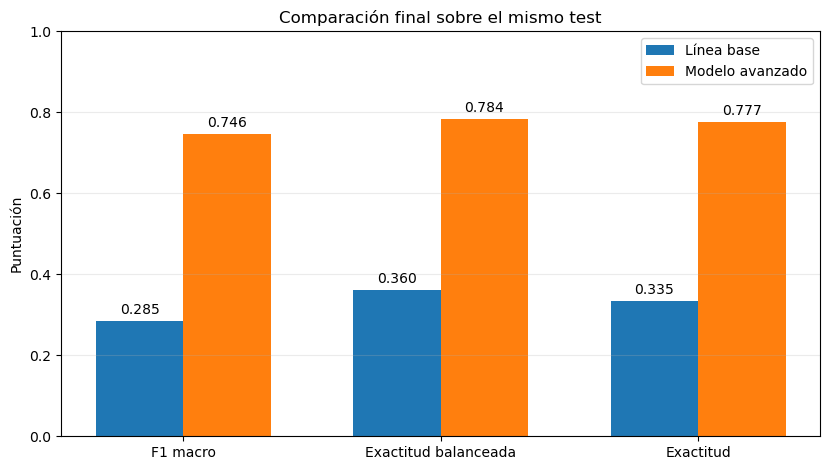

In [12]:
comparison = pd.DataFrame([
    {"Modelo": "HOG + LinearSVC", **final_result["baseline_test"]},
    {"Modelo": "EfficientNet-B0 seleccionada", **final_result["advanced_test"]},
]).rename(columns={
    "accuracy": "Exactitud",
    "balanced_accuracy": "Exactitud balanceada",
    "precision_macro": "Precisión macro",
    "recall_macro": "Recall macro",
    "f1_macro": "F1 macro",
})
display(comparison[[
    "Modelo", "F1 macro", "Exactitud balanceada", "Exactitud", "Precisión macro", "Recall macro",
]])

ci_low, ci_high = final_result["paired_bootstrap"]["ci95"]
print(
    f"Mejora absoluta en F1 macro: {final_result['absolute_improvement']['f1_macro']:+.4f}\n"
    f"Intervalo bootstrap pareado del 95 %: [{ci_low:.4f}, {ci_high:.4f}]"
)

metrics_to_plot = ["F1 macro", "Exactitud balanceada", "Exactitud"]
x = np.arange(len(metrics_to_plot))
width = 0.34
figure, axis = plt.subplots(figsize=(8.4, 4.8))
base_bars = axis.bar(x - width/2, comparison.loc[0, metrics_to_plot], width, label="Línea base")
advanced_bars = axis.bar(x + width/2, comparison.loc[1, metrics_to_plot], width, label="Modelo avanzado")
axis.bar_label(base_bars, fmt="%.3f", padding=3)
axis.bar_label(advanced_bars, fmt="%.3f", padding=3)
axis.set_xticks(x, metrics_to_plot)
axis.set_ylim(0, 1)
axis.set_title("Comparación final sobre el mismo test")
axis.set_ylabel("Puntuación")
axis.grid(axis="y", alpha=0.25)
axis.legend()
plt.tight_layout()
plt.show()

## 7. Análisis de errores

La métrica global se complementa con el comportamiento por clase y una matriz de confusión normalizada. Esta revisión permite distinguir entre clases que se sobrepredicen y clases cuyos ejemplos se pierden con frecuencia.

,clase,precision,recall,f1,soporte,f1_linea_base,diferencia_f1
1,Cable,0.3448,0.9091,0.5000,22,0.2308,0.2692
4,Mobile,0.5405,0.9581,0.6911,167,0.4482,0.2429
3,Laptop,0.9808,0.6220,0.7612,82,0.3094,0.4518
2,Keyboard,0.8621,0.7042,0.7752,71,0.3392,0.4360
6,PCB,0.9904,0.6754,0.8031,305,0.1471,0.6561
5,Mouse,0.8901,0.7788,0.8308,104,0.1000,0.7308
0,Battery,0.8836,0.8402,0.8613,244,0.4196,0.4418


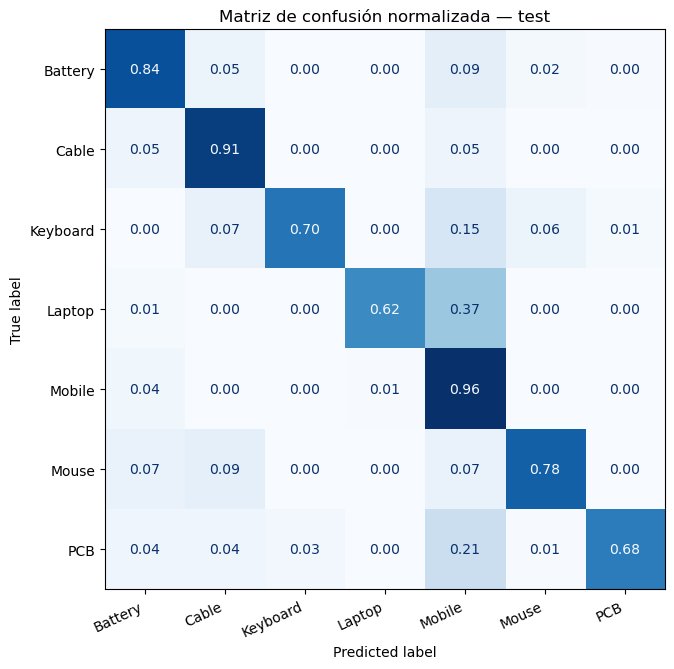

Clases con menor F1: Cable, Mobile, Laptop.
Brecha entre validación y test: -0.1316.


In [13]:
advanced_classes = pd.DataFrame(final_result["advanced_per_class"])
baseline_classes = pd.read_csv(BASELINE_ROOT / "metricas_por_clase_test.csv")
class_comparison = advanced_classes.merge(
    baseline_classes[["clase", "f1"]].rename(columns={"f1": "f1_linea_base"}), on="clase"
)
class_comparison["diferencia_f1"] = class_comparison["f1"] - class_comparison["f1_linea_base"]
display(class_comparison.sort_values("f1"))

truth = final_result["truth"]
predicted = final_result["predicted"]
matrix = confusion_matrix(truth, predicted, labels=range(len(CLASSES)), normalize="true")
figure, axis = plt.subplots(figsize=(8.2, 6.8))
ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(
    ax=axis, cmap="Blues", values_format=".2f", colorbar=False
)
axis.set_title("Matriz de confusión normalizada — test")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

validation_f1 = finetune_result["selected_validation"]["f1_macro"]
test_f1 = final_result["advanced_test"]["f1_macro"]
weakest = class_comparison.nsmallest(3, "f1")["clase"].tolist()
print(f"Clases con menor F1: {', '.join(weakest)}.")
print(f"Brecha entre validación y test: {test_f1 - validation_f1:+.4f}.")

### Interpretación

El ajuste fino no mejoró la referencia de validación: las épocas adicionales redujeron F1 mientras el entrenamiento continuó avanzando. Por esa razón se conservó el checkpoint E03 anterior a la liberación de bloques. Esta decisión muestra la función real de la parada temprana: no obliga a aceptar una etapa más compleja cuando la evidencia indica peor generalización.

En test, `Cable` obtiene *recall* alto con precisión baja, señal de que el modelo recupera la mayoría de los cables pero también asigna esa clase a objetos de otras categorías. `Mobile` presenta un patrón similar, aunque menos extremo. `Laptop` y `PCB` muestran precisión alta con *recall* menor, por lo que sus predicciones positivas suelen ser correctas, pero todavía se pierden casos reales. La brecha entre validación y test evidencia cambio entre grupos de procedencia, aun cuando el modelo seleccionado supera ampliamente la línea base.

Las mejoras futuras deberían ampliar las categorías minoritarias, revisar ejemplos ambiguos y estudiar calibración o abstención. Esas decisiones pertenecen a un nuevo ciclo: el test de esta entrega queda congelado y no se utilizará para escoger otra arquitectura.

## 8. Conclusiones

La configuración E03 alcanzó un F1 macro de validación de **0,8777**, apenas **0,0008** por encima de E01. El ajuste fino fue descartado porque no superó ese checkpoint. Sobre 995 imágenes de prueba, el modelo seleccionado obtuvo **0,7461** de F1 macro y **0,7769** de exactitud, frente a **0,2849** y **0,3347** de HOG + LinearSVC. La mejora absoluta de F1 fue **0,4612**, con un intervalo *bootstrap* pareado del 95 % entre **0,4237** y **0,5022**.

El resultado confirma una mejora cuantificable sin ocultar sus límites. El descenso entre validación y test fue de **0,1316** puntos de F1 macro y `Cable` continúa siendo la categoría más difícil. Por tanto, el modelo es una referencia experimental sólida dentro de ETID, pero requiere validación externa antes de utilizarse en un punto de recepción real.

## 9. Reproducibilidad y control de cierre

La última celda registra hashes, versiones y el cumplimiento de los cinco criterios centrales de la rúbrica. Una falla detiene la ejecución para evitar entregar resultados incompletos.

In [14]:
source_hash = hashlib.sha256("\n\n".join(
    cell for cell in globals().get("_ih", []) if isinstance(cell, str)
).encode("utf-8")).hexdigest() if "_ih" in globals() else "Disponible al guardar el notebook"

checks = {
    "Pipeline avanzado implementado": len(experiment_results) == 3,
    "Búsqueda controlada documentada": ranking["Experimento"].nunique() == 3,
    "Curvas de pérdida, exactitud y F1": all(len(result["history"]) >= 1 for result in experiment_results),
    "Ajuste fino con parada temprana": finetune_result["status"] == "COMPLETE",
    "Checkpoint íntegro": sha256(selected_checkpoint) == finetune_result["selected_checkpoint_sha256"],
    "Test ajeno a la selección": final_result["test_used_for_training_or_selection"] is False,
    "Comparación directa con baseline": "f1_macro" in final_result["absolute_improvement"],
    "Análisis por clase": len(final_result["advanced_per_class"]) == len(CLASSES),
}
closure = pd.DataFrame({"Criterio": checks.keys(), "Cumple": checks.values()})
display(closure)
assert all(checks.values()), "La auditoría detectó elementos pendientes."

reproducibility = {
    "seed": SEED,
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "scikit_learn": sklearn.__version__,
    "train_manifest_sha256": sha256(SPLITS_ROOT / "train.csv"),
    "validation_manifest_sha256": sha256(SPLITS_ROOT / "validation.csv"),
    "test_manifest_sha256": sha256(SPLITS_ROOT / "test.csv"),
    "selected_checkpoint_sha256": sha256(selected_checkpoint),
    "notebook_history_sha256": source_hash,
}
save_json(RUN_ROOT / "reproducibility.json", reproducibility)
display(pd.Series(reproducibility, name="Valor").to_frame())
print("Auditoría superada. Guarde el notebook con todas las salidas visibles.")

,Criterio,Cumple
0,Pipeline avanzado implementado,True
1,Búsqueda controlada documentada,True
2,"Curvas de pérdida, exactitud y F1",True
3,Ajuste fino con parada temprana,True
4,Checkpoint íntegro,True
5,Test ajeno a la selección,True
6,Comparación directa con baseline,True
7,Análisis por clase,True


,Valor
seed,20261017
python,3.10.18
platform,Windows-10-10.0.26200-SP0
torch,2.6.0+cu126
torchvision,0.21.0+cu126
scikit_learn,1.7.2
train_manifest_sha256,b0759318003bab059154a48de9e1bff47fbc02cb4e70e7...
validation_manifest_sha256,bb17b6d7c7d398d02f847b2114d5d574e028dd8756a17a...
test_manifest_sha256,e63e149a2417fb4773121710248fef286f9ab908d7133b...
selected_checkpoint_sha256,9d5361fed4282fdbe5744f3e559cea4ecb7a2525986999...


Auditoría superada. Guarde el notebook con todas las salidas visibles.


## Referencias

Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2021). Datasheets for datasets. *Communications of the ACM, 64*(12), 86–92. https://doi.org/10.1145/3458723

Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press. https://www.deeplearningbook.org/

Google Developers. (s. f.). *A scientific approach to improving model performance*. Machine Learning Guides. https://developers.google.com/machine-learning/guides/deep-learning-tuning-playbook/scientific

Scikit-learn Developers. (s. f.). *Cross-validation: Evaluating estimator performance*. https://scikit-learn.org/stable/modules/cross_validation.html

Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press. https://www.deeplearningbook.org/

Tan, M., & Le, Q. V. (2019). EfficientNet: Rethinking model scaling for convolutional neural networks. *Proceedings of the 36th International Conference on Machine Learning, 97*, 6105–6114. https://proceedings.mlr.press/v97/tan19a.html